In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys
from hnn_tuning import REPO_ROOT
pth = str(REPO_ROOT)

sys.path.append(pth)

import hnn_core

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from hnn_tuning import results_dir

figpth = results_dir('network_sim', 'ERP')

# The number of cores may need modifying depending on your current machine.
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'
import matplotlib

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

n_procs=10
cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

In [2]:
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(-500,2500,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)
weights_ampa_p1 = {'L2_inhibitory': 0.0, 
                   'L2_pyramidal': 0.015,
                   'L5_inhibitory': 0.00, 
                   'L5_pyramidal': 0.00}
weights_nmda_p1 = {'L2_inhibitory': 0.0, 'L2_pyramidal': 0.015,
                   'L5_inhibitory': 0.0, 'L5_pyramidal': .0}
synaptic_delays_prox = {'L2_inhibitory': 0.1, 'L2_pyramidal': .1,
                        'L5_inhibitory': 1., 'L5_pyramidal': 1.}

net.add_evoked_drive('prox1', mu=15, sigma=3.5, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal', synaptic_delays=synaptic_delays_prox)

# weights_ampa_d1 = {'L2_inhibitory': 0.005, 'L2_pyramidal': 0.01, 'L5_pyramidal': 1.}
# weights_nmda_d1 = {'L2_inhibitory': 0.0, 'L2_pyramidal': .01, 'L5_pyramidal': 1.}
# synaptic_delays_dist = {'L2_inhibitory': 0.1, 'L2_pyramidal': 0.1,'L5_pyramidal': 0.1}

# net.add_evoked_drive('dist1', mu=56, sigma=4.5, numspikes=2, weights_ampa=weights_ampa_d1,
#     weights_nmda=weights_nmda_d1, location='distal', synaptic_delays=synaptic_delays_dist)

# weights_ampa_p2 = {'L2_inhibitory': 0.0, 'L2_pyramidal':0.305,
#                    'L5_inhibitory': 0.044, 'L5_pyramidal': 0.051}
# weights_nmda_p2 = {'L2_inhibitory': 0.86, 'L2_pyramidal': 0.0001,
#                    'L5_inhibitory': 5e-7, 'L5_pyramidal': 0.38}
# synaptic_delays_prox = {'L2_inhibitory': 0.1, 'L2_pyramidal': .1,
#                         'L5_inhibitory': 1., 'L5_pyramidal': 1.}
# net.add_evoked_drive('prox2', mu=99, sigma=12, numspikes=1, weights_ampa=weights_ampa_p2,
#     weights_nmda=weights_nmda_p2, location='proximal', synaptic_delays=synaptic_delays_prox)


with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=100, n_trials=1,bsl_cor='duecker')

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from 

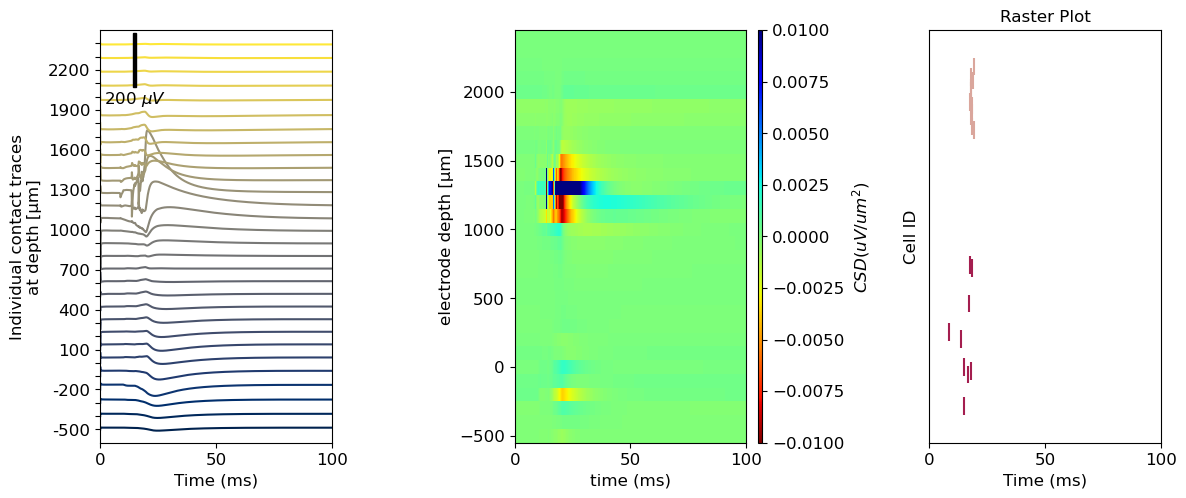

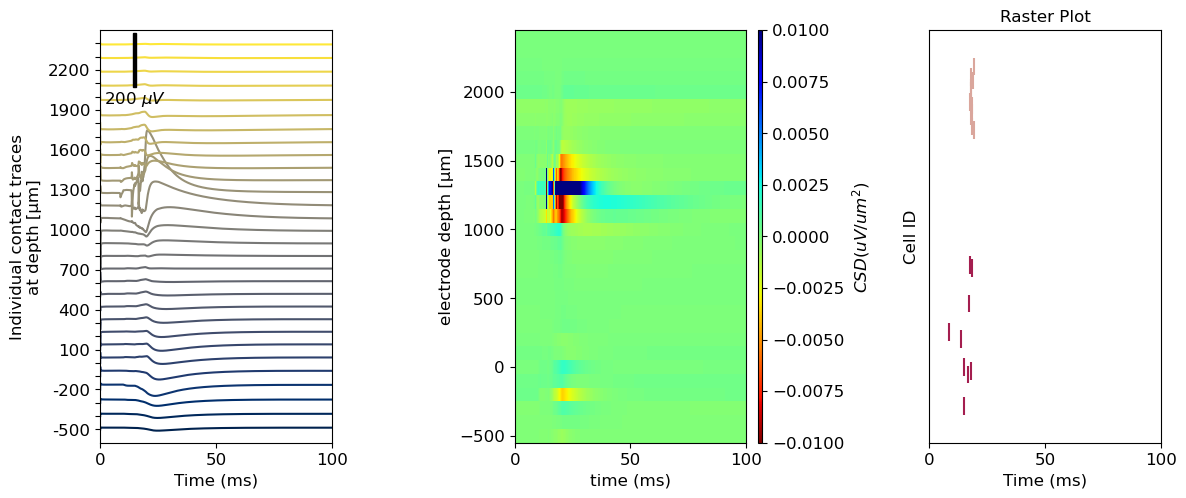

In [3]:
electrode_data = net.rec_arrays['probe1'][0]

fig, ax = plt.subplots(1,3,figsize=(12,5))
electrode_data.plot_lfp(show=False, ax=ax[0])
electrode_data.plot_csd(show=False, ax=ax[1], sink='r', vmin=-0.01, vmax=0.01, interpolation=None)
net.cell_response.plot_spikes_raster(ax=ax[2], show_legend=False, )

# Prox1 AMPA L2/3 only: 